In [141]:
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from typing import TypedDict, Literal
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq

In [142]:
load_dotenv()

True

In [143]:
model = ChatGroq(
    model="openai/gpt-oss-20b"
)

In [145]:
class TicketSchema(BaseModel):
    categories: Literal['Technical', 'Billing', 'Critical', 'General'] = Field(description="The category of the issue mentioned in the ticket")

In [146]:
class CustomerSupport(TypedDict):
    ticket: str
    category: str
    result: str

In [147]:
structured_model = model.with_structured_output(TicketSchema)

In [52]:
prompt = 'I have been facing issues with my bill submission.'

result = structured_model.invoke(prompt)

print(result)

categories='Billing'


In [10]:
result.categories

'Billing'

In [159]:
def classify_ticket(state: CustomerSupport):

    prompt = f"Take the following ticket {state['ticket']}. Identify the category of the ticket."

    response = structured_model.invoke(prompt)

    return {'category': response.categories}
        

In [160]:
def route_ticket(state: CustomerSupport) -> Literal['technical_problem', 'billing_problem', 'critical_problem', 'general_problem']:
    if state['category'] == 'Technical':
        return 'technical_problem'
    elif state['category'] == 'Billing':
        return 'billing_problem'
    elif state['category'] == 'Critical':
        return 'critical_problem'
    else:
        return 'general_problem'

In [183]:
def technical_problem(state: CustomerSupport):
    technical_prompt = f"""
    You are a technical support assistant.
    Help the customer solve their technical issue.
    Provide a simple and clear solution.

    Customer query: {state['ticket']}
    """

    response = model.invoke(technical_prompt)

    return {'result': response.content}



In [184]:
def billing_problem(state: CustomerSupport):
    billing_prompt = f"""
You are a billing support assistant.
Help the customer with billing, payments, and refunds.
Provide a helpful response.

Customer query: {state['ticket']}
"""

    response = model.invoke(billing_prompt)

    return {'result': response.content}



In [185]:
def critical_problem(state: CustomerSupport):
    critical_prompt = f"""
You are a critical incident support assistant.
Analyze the reported urgent issue.
Explain the immediate steps the customer should take.

Customer query: {state['ticket']}
"""

    response = model.invoke(critical_prompt)

    return {'result': response.content}



In [186]:
def general_problem(state: CustomerSupport):
    general_prompt = f"""
You are a general customer support assistant.
Answer the customer's question clearly and politely.

Customer query: {state['ticket']}
"""

    response = model.invoke(general_prompt)

    return {'result': response.content}



In [187]:
graph = StateGraph(CustomerSupport)

graph.add_node('classify_ticket', classify_ticket)
graph.add_node('technical_problem', technical_problem)
graph.add_node('billing_problem', billing_problem)
graph.add_node('critical_problem', critical_problem)
graph.add_node('general_problem', general_problem)

graph.add_edge(START, 'classify_ticket')
graph.add_conditional_edges('classify_ticket', route_ticket,{'technical_problem': 'technical_problem', 'billing_problem':'billing_problem', 'critical_problem': 'critical_problem', 'general_problem':'general_problem'})
graph.add_edge('technical_problem', END)
graph.add_edge('billing_problem', END)
graph.add_edge('critical_problem', END)
graph.add_edge('general_problem', END)

In [188]:
workflow = graph.compile()

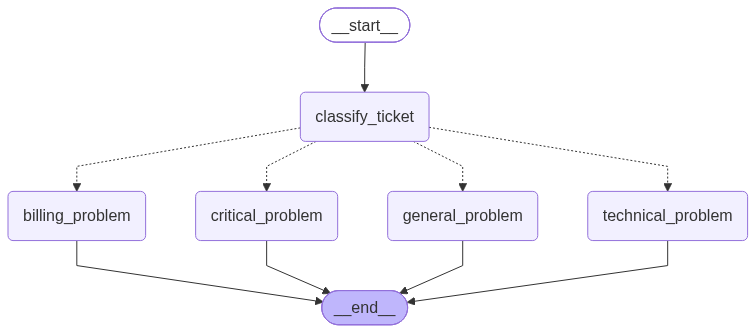

In [189]:
workflow

In [190]:
initial_state = {
    'ticket': 'I have been facing issues with my bill submission.'
}

In [191]:
result = workflow.invoke(initial_state)

In [193]:
result

{'ticket': 'I have been facing issues with my bill submission.',
 'category': 'Billing',
 'result': 'Hi there! I’m sorry to hear you’re having trouble submitting your bill. Let’s get this sorted out together.\n\n### Quick Checklist\n\n| Step | What to do | Common issue it fixes |\n|------|------------|-----------------------|\n| 1 | **Confirm the file format** | Bills must be in PDF, JPG, PNG, or CSV. |\n| 2 | **Check file size** | Most portals limit uploads to 10\u202fMB. |\n| 3 | **Make sure the bill is complete** | All required fields (date, amount, account number) must be visible. |\n| 4 | **Use the correct upload portal** | Go to **My Account → Billing → Upload Bill**. |\n| 5 | **Clear your browser cache** | Old cookies can cause upload errors. |\n| 6 | **Try a different browser or device** | Some browsers block file uploads. |\n\n### If the upload still fails\n\n1. **Error message?**  \n   - If you see a specific error code or message, let me know.  \n   - Example: “Upload failed